# KDDM Phase 1 — Ice Hockey Talent Scouting

**Group 174**

| Student | Matriculation Number |
| --- | --- |
| Muhammad Saim Akram | 12344542 |
| Zamarak Sufyan |  |

This notebook does the Phase 1 part of the project: loading the 7 data files, cleaning them up, joining them into one big table, and making some plots.

The dataset has information about 10,000 ice hockey players. The goal of Phase 1 is just to clean the data — we don't have the answer column yet (that comes in Phase 2). The data is split across 7 different files in 5 different formats, and many of the columns are messy on purpose, so we have to figure out how to fix all of that.


## Step 1: Importing the libraries we need

We are going to use:

- **pandas** to load and work with the tables
- **numpy** for some math things like NaN
- **matplotlib** for making the plots
- **os** so we can build file paths

We also import `display` from IPython so that tables print nicely in the notebook.


In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

# This makes pandas show all columns when we print a table
pd.set_option("display.max_columns", None)

# Where the data files live, and where to save things
data_folder = "data"
output_folder = "data/newdata"
figures_folder = "docs/figures"

# Make sure the output folders exist
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
if not os.path.exists(figures_folder):
    os.makedirs(figures_folder)

print("Libraries loaded. Data folder:", data_folder)


Libraries loaded. Data folder: data


## Step 2: Loading all 7 data files

Each file has a different format, so we need a different pandas function for each one:

- `.tsv` files are tab-separated, so we use `pd.read_csv` with `sep="\t"`
- `.csv` files are comma-separated, so we use plain `pd.read_csv`
- `.pkl` files are pandas pickle files, so we use `pd.read_pickle`
- `.xlsx` files are Excel files, so we use `pd.read_excel`
- `.json` files are JSON, so we use `pd.read_json`


In [2]:
performance = pd.read_csv("data/performance.tsv", sep="\t")
contracts = pd.read_pickle("data/contracts_competition.pkl")
scouting = pd.read_csv("data/hockey_scouting_notes.csv")
identity_1 = pd.read_csv("data/identity_card_1.csv")
identity_0 = pd.read_csv("data/identity_card_0.tsv", sep="\t")
medical = pd.read_excel("data/medical_information.xlsx")
moms_notes = pd.read_json("data/moms_notes.json")

print("All 7 files loaded.")


All 7 files loaded.


## Step 3: Taking a first look at each file

Before we change anything, we want to see what we are working with. For each file we will:

1. Print its shape (how many rows and columns)
2. Show the first few rows with `.head()`
3. Check how many missing values it has with `.isnull().sum()`

This way we know what problems we need to fix later.


### Performance file

In [3]:
print("Shape:", performance.shape)
display(performance.head())
print("\nMissing values per column:")
print(performance.isnull().sum())


Shape: (10000, 29)


,international_id,goals,assists,num_of_shots,shot_speed,shot_attempts,shooting_percentage,high_danger_shots,medium_danger_shots,low_danger_shots,save_percentage,winning_goals,power_play_time,power_play_goals,time_on_ice,faceoff_win_percentage,puck_touches,puck_recoveries,puck_possession_time,penalty_kill_time,penality_minutes,penalties_taken,time_between_penalties,goals_against_total,goals_against_average,passes_attempted,passes_completed,pass_completion_rate,games_missed_due_to_injury
0,6938,166.0,244.0,461.0,130.6172,480.0,12.6758,158.0,185.0,137.0,63.9321,7.0,1.8632,190.0,9.60,45.4934,900.0,142.0,10.24,3.23,13.0,0.0,8.02,0.0,0.0,759.0,148.0,19.50,28.0
1,3924,98.0,166.0,459.0,76.4679,490.0,10.1533,142.0,186.0,162.0,55.3581,6.0,3.8182,107.0,3.85,59.3460,344.0,138.0,0.00,3.47,2.0,1.0,1.14,0.0,0.0,456.0,354.0,77.63,21.0
2,3365,87.0,167.0,439.0,82.1817,449.0,33.3924,134.0,165.0,150.0,80.0563,3.0,2.5411,104.0,27.80,56.1291,57.0,78.0,18.94,0.00,8.0,0.0,54.28,0.0,0.0,371.0,171.0,46.09,19.0
3,1284,93.0,155.0,447.0,73.0825,447.0,30.7875,141.0,136.0,170.0,72.6164,4.0,5.0928,101.0,17.08,54.0498,146.0,296.0,0.00,1.81,16.0,1.0,8.89,0.0,0.0,411.0,137.0,33.33,17.0
4,5333,104.0,169.0,496.0,75.9673,503.0,42.2507,188.0,163.0,152.0,70.3253,0.0,1.5467,115.0,13.02,49.7741,200.0,183.0,0.00,4.78,0.0,0.0,18.33,0.0,0.0,455.0,183.0,40.22,18.0



Missing values per column:
international_id               0
goals                         37
assists                       37
num_of_shots                  37
shot_speed                    37
shot_attempts                 37
shooting_percentage           37
high_danger_shots             37
medium_danger_shots           37
low_danger_shots              37
save_percentage               37
winning_goals                 37
power_play_time               37
power_play_goals              37
time_on_ice                   37
faceoff_win_percentage        37
puck_touches                  37
puck_recoveries               37
puck_possession_time          37
penalty_kill_time             37
penality_minutes              37
penalties_taken               37
time_between_penalties        37
goals_against_total           37
goals_against_average         37
passes_attempted              37
passes_completed              37
pass_completion_rate          37
games_missed_due_to_injury    37
dtype: int64


### Contracts file

In [4]:
print("Shape:", contracts.shape)
display(contracts.head())
print("\nMissing values per column:")
print(contracts.isnull().sum())


Shape: (10000, 8)


,international_id,contracts_signed,salary,captain,won_championship,jersey_number,draft_year,number_of_previous_teams
0,6032,5.0,669578.77,False,True,48.0,2022.0,12.0
1,3654,5.0,1647102.80,False,False,10.0,2013.0,15.0
2,8729,6.0,1678593.48,False,False,63.0,2016.0,14.0
3,2300,1.0,927858.79,False,False,46.0,2015.0,8.0
4,8407,2.0,710328.25,True,True,79.0,2012.0,15.0



Missing values per column:
international_id              0
contracts_signed            122
salary                       37
captain                      37
won_championship             37
jersey_number                37
draft_year                   37
number_of_previous_teams    206
dtype: int64


### Identity card 1 (the normal one)

In [5]:
print("Shape:", identity_1.shape)
display(identity_1.head())
print("\nMissing values per column:")
print(identity_1.isnull().sum())


Shape: (9112, 8)


,international_id,medical_id,first_name,last_name,gender,age,birth_city,nationality
0,3731,c408fbd0-cac8-4950-92e8-ea7c73fa1361,Preston,Mick,male,23.0,Trondheim,norway
1,1628,66522ba9-e5a0-4f3c-821f-41ed0d65d3ca,Wilbur,Moore,male,20.0,Marseille,U.S.A
2,7448,e417f30c-187d-4ef9-8c41-ee3bf255baea,Jeffrey,Kindrick,male,25.0,Boston,usa
3,3922,feb6dc99-908d-44c7-be73-397404be5bf1,Vanessa,Hawkins,other,31.0,Liberec,czechia
4,9394,5336e053-fdd3-4312-b475-d11c6bb783d8,Crystal,Green,female,22.0,Moscow,russia



Missing values per column:
international_id     0
medical_id           0
first_name          37
last_name           37
gender              37
age                 37
birth_city          37
nationality         37
dtype: int64


### Identity card 0 (the weird one with Latin words)

In [6]:
print("Shape:", identity_0.shape)
display(identity_0.head())
print("\nThe column names are in Latin and the ID column is in Roman numerals!")


Shape: (888, 8)


,numerus_internationalis_ad_identitatem,numerus_identificationis_ad_medicinam,praenomen,cognomen,sexus,aetas_annorum,urbs_natalis,natio
0,CCLXXV,039e0ab7-e36d-4bc7-a0b1-3e93e8ec73e9,Keithus,Alleeius,male,23.0,vienna,austria
1,MMDLX,070dfb40-76c9-4894-90e5-7463d060d49b,Alyssa,Kohlius,f,31.0,Vienna,austria
2,MMCCCXXIII,fa06ed07-6f09-4ec2-9f11-a70917307270,Emily,Belangerius,female,29.0,OSTRAVA,france
3,MMMMMMMDCCVIII,59f94605-e953-4117-b9ee-09ba1392e895,Stefanie,Fiedlerius,female,25.0,rome,italy
4,MMMMLXII,2e663575-2f96-42fc-ab59-481993a65a53,Melanie,Mulliganius,female,312.0,Paris,france



The column names are in Latin and the ID column is in Roman numerals!


### Medical file (the Excel file with weird header)

In [7]:
print("Shape:", medical.shape)
display(medical.head())
print("\nNotice that the column names look strange - the first row contains the real headers, not the column index.")


Shape: (10002, 11)


,Unnamed: 0,"Date: 2026-03-31 | Meta Data: ""I'm a doctor, not an engineer"" ~McCoy",Unnamed: 2,Unnamed: 3,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,Unnamed: 10
0,NaN,height,weight,age_in_years,shoe_size,body_fat_percentage,fitness_level,sprint_time,medical_information,return_date,physician_signature
1,medical_id,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,368bcbfc-cc90-43da-841f-aa57d4d789c7,1.79m,82.4772kg,24,40.7,20.87%,Average,3.9727,NaN,2025-01-12,"Dr. sth., MD"
3,f7164dc2-6646-420e-b6b5-42fc07c11f6d,180.1135cm,93.8985,29,40.3,23.38,NaN,4.1549,NaN,2025-01-02,"Dr. sth., MD"
4,09c9de13-5d3a-4b75-a7ec-ce10bb32efdd,163.1483cm,79.2438,25,37.2,23.41,good,4.0825,NaN,2025-01-17,Mr. Many good sounding titles



Notice that the column names look strange - the first row contains the real headers, not the column index.


### Scouting notes file

In [8]:
print("Shape:", scouting.shape)
display(scouting.head())
print("\nMissing values per column:")
print(scouting.isnull().sum())


Shape: (10000, 7)


,international_id,position,dominant_hand,experience_level,years_played,years_pro,scout_notes
0,2991,defense,left,veteran,8.0,8.0,"effort varies throughout the game, awkward str..."
1,3042,right wing,right,veteran,0.0,0.0,a consistent performer who can be counted on i...
2,3761,right wing,right,veteran,0.0,0.0,late support on breakouts
3,6229,left wing,left,rookie,1.0,1.0,NaN
4,1303,defense,NaN,veteran,9.0,9.0,"poor awareness in defensive zone, strong and a..."



Missing values per column:
international_id       0
position              37
dominant_hand        651
experience_level      37
years_played          37
years_pro             37
scout_notes         1038
dtype: int64


### Mom's notes file

In [9]:
print("Shape:", moms_notes.shape)
display(moms_notes.head())
print("\nNote: this file does NOT have an international_id column, so we will need a different way to join it later.")


Shape: (10000, 13)


,first_name,last_name,age,birth_city,school_grade,years_in_usa,eye_color,stuffed_animal_name,favourite_board_game,personal_notes,favourite_child_info,favourite_tv_show,favourite_food
0,Edward,Battey,21.0,Stockholm,3.51,0.0,HAZEL,Dawn,Attack!,None,"I have no favourite child, I love them all equ...",,
1,Winifred,Bien,19.0,Oslo,3.02,2.0,HAZEL,John,Dungeons & Dragons,gently reflective in life,"I have no favourite child, I love them all equ...",,
2,None,None,NaN,None,NaN,NaN,None,None,None,None,"I have no favourite child, I love them all equ...",,
3,Carolyn,Gaudino,27.0,kosice,2.61,0.0,brown,Jeff,Dungeons & Dragons,None,"I have no favourite child, I love them all equ...",,
4,Christopher,Goode,26.0,Budapest,2.60,3.0,brown,Irma,Dungeons & Dragons,gently introspective most days,"I have no favourite child, I love them all equ...",,



Note: this file does NOT have an international_id column, so we will need a different way to join it later.


### What we learned from looking at the files

- `performance.tsv`, `contracts_competition.pkl`, `hockey_scouting_notes.csv` and `identity_card_1.csv` all have a column called `international_id` that we can use to join them.
- `identity_card_0.tsv` is the same kind of data as `identity_card_1`, but the column names are in Latin and the IDs are Roman numerals. We need to fix it.
- `medical_information.xlsx` has a broken header. We need to re-read it.
- `moms_notes.json` has no ID column, so we will have to join by first name and last name.
- Lots of the columns have missing values. We will handle them later.


## Step 4: Fixing identity_card_0 (Latin words + Roman numerals)

The columns are in Latin (`praenomen` instead of `first_name`, etc.), the IDs are Roman numerals like `CCLXXV`, and some of the names have Latin endings (`Keithus` instead of `Keith`). We have to fix all three things.


### 4a: Renaming the Latin column names to English

In [10]:
# A dictionary that says what each Latin name should become in English
latin_to_english = {
    "numerus_internationalis_ad_identitatem": "international_id",
    "numerus_identificationis_ad_medicinam": "medical_id",
    "praenomen": "first_name",
    "cognomen": "last_name",
    "sexus": "gender",
    "aetas_annorum": "age",
    "urbs_natalis": "birth_city",
    "natio": "nationality",
}

identity_0 = identity_0.rename(columns=latin_to_english)
print("Columns after renaming:")
print(identity_0.columns.tolist())


Columns after renaming:
['international_id', 'medical_id', 'first_name', 'last_name', 'gender', 'age', 'birth_city', 'nationality']


### 4b: Converting the Roman numerals to normal numbers

For example, `CCLXXV` should become `275`.

The rules of Roman numerals are: I = 1, V = 5, X = 10, L = 50, C = 100, D = 500, M = 1000. When a smaller letter comes BEFORE a bigger one, you subtract it (so IV = 4, IX = 9). Otherwise you add.

We will write a small function that does this, and then apply it to every value in the column.


In [11]:
def roman_to_number(roman_string):
    # If the value is missing, return missing
    if pd.isna(roman_string):
        return np.nan

    # The values of each letter
    letter_values = {"I": 1, "V": 5, "X": 10, "L": 50, "C": 100, "D": 500, "M": 1000}

    total = 0
    previous_value = 0

    # We read the Roman number from right to left.
    # If the current letter is smaller than the one to its right, we subtract.
    # Otherwise we add.
    for letter in reversed(str(roman_string).strip().upper()):
        if letter not in letter_values:
            return np.nan
        current_value = letter_values[letter]
        if current_value < previous_value:
            total = total - current_value
        else:
            total = total + current_value
        previous_value = current_value

    return total


# Apply the function to every row in the international_id column
identity_0["international_id"] = identity_0["international_id"].apply(roman_to_number)

print("First few converted IDs:")
print(identity_0[["international_id", "first_name", "last_name"]].head())


First few converted IDs:
   international_id first_name    last_name
0               275    Keithus     Alleeius
1              2560     Alyssa      Kohlius
2              2323      Emily  Belangerius
3              7708   Stefanie   Fiedlerius
4              4062    Melanie  Mulliganius


### 4c: Removing the Latin endings from the names

Some names end with `-ius` (like `Kohlius` → `Kohl`) or `-us` (like `Keithus` → `Keith`). We need to remove those endings so the names match the ones in `moms_notes.json`.


In [12]:
def strip_latin_ending(name):
    if pd.isna(name):
        return name
    name = str(name)
    # Check the longer ending first ('ius'), then the shorter one ('us')
    if name.endswith("ius"):
        return name[:-3]
    if name.endswith("us"):
        return name[:-2]
    return name


identity_0["first_name"] = identity_0["first_name"].apply(strip_latin_ending)
identity_0["last_name"] = identity_0["last_name"].apply(strip_latin_ending)

print("Names after stripping Latin endings:")
print(identity_0[["first_name", "last_name"]].head(10))


Names after stripping Latin endings:
  first_name last_name
0      Keith     Allee
1     Alyssa      Kohl
2      Emily  Belanger
3   Stefanie   Fiedler
4    Melanie  Mulligan
5   Brittany    Meeker
6      David   Walters
7      Betty    Bailey
8     Donald    Ridder
9    Beverly   Haywood


## Step 5: Combining the two identity tables

Now that `identity_0` has the same column names and the same kind of IDs as `identity_1`, we can stack them on top of each other with `pd.concat`. We expect the result to have 10,000 rows (888 + 9,112).


In [13]:
identity = pd.concat([identity_0, identity_1], ignore_index=True)

print("Combined identity table shape:", identity.shape)
print("Number of unique international_ids:", identity["international_id"].nunique())


Combined identity table shape: (10000, 8)
Number of unique international_ids: 10000


## Step 6: Cleaning the medical Excel file

The Excel file has a strange header layout. The real column names are in row 0, the label `medical_id` sits alone in row 1 column 0, and row 2 is some metadata. So we need to re-read the file with `header=None` and rebuild the column names ourselves.


### 6a: Re-reading with a fixed header

In [14]:
# Re-read the medical file WITHOUT pandas guessing the header
medical_raw = pd.read_excel("data/medical_information.xlsx", header=None)

# Look at what's in there
print("First 4 rows of the raw file:")
display(medical_raw.head(4))


First 4 rows of the raw file:


,0,1,2,3,4,5,6,7,8,9,10
0,NaN,"Date: 2026-03-31 | Meta Data: ""I'm a doctor, n...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,height,weight,age_in_years,shoe_size,body_fat_percentage,fitness_level,sprint_time,medical_information,return_date,physician_signature
2,medical_id,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,368bcbfc-cc90-43da-841f-aa57d4d789c7,1.79m,82.4772kg,24,40.7,20.87%,Average,3.9727,NaN,2025-01-12,"Dr. sth., MD"


In [15]:
# Build the real column names: 'medical_id' for the first column,
# and the names from row 1 for the rest
column_names = ["medical_id"] + medical_raw.iloc[1, 1:].tolist()
print("Column names will be:")
print(column_names)

# Now keep only the actual data rows (starting from row 3) and use our column names
medical = medical_raw.iloc[3:].reset_index(drop=True).copy()
medical.columns = column_names

print("\nMedical table after fixing the header:")
display(medical.head())


Column names will be:
['medical_id', 'height', 'weight', 'age_in_years', 'shoe_size', 'body_fat_percentage', 'fitness_level', 'sprint_time', 'medical_information', 'return_date', 'physician_signature']

Medical table after fixing the header:


,medical_id,height,weight,age_in_years,shoe_size,body_fat_percentage,fitness_level,sprint_time,medical_information,return_date,physician_signature
0,368bcbfc-cc90-43da-841f-aa57d4d789c7,1.79m,82.4772kg,24,40.7,20.87%,Average,3.9727,NaN,2025-01-12,"Dr. sth., MD"
1,f7164dc2-6646-420e-b6b5-42fc07c11f6d,180.1135cm,93.8985,29,40.3,23.38,NaN,4.1549,NaN,2025-01-02,"Dr. sth., MD"
2,09c9de13-5d3a-4b75-a7ec-ce10bb32efdd,163.1483cm,79.2438,25,37.2,23.41,good,4.0825,NaN,2025-01-17,Mr. Many good sounding titles
3,be8969bf-6de2-49fd-b0e9-c014bdb970d6,1.82m,80.8913kg,29,42.5,21.28%,Good,3.5001,NaN,2025/01/05,unintelligible handwriting
4,476cd0f0-0154-4e70-be7c-661007e7fcc4,167.7038cm,109.2016,25,37.3,31.71,excellent,3.7619,NaN,2025-01-02,unintelligible handwriting


### 6b: Fixing the height column

The height values are written in two different ways: some have `cm` at the end (like `180.1135cm`) and some have `m` (like `1.79m`). We will convert everything to centimeters.


In [16]:
def fix_height(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    # If the text contains 'nan', treat as missing
    if "nan" in text:
        return np.nan
    # If it ends with 'cm', remove the 'cm' and convert to a number
    if text.endswith("cm"):
        return float(text[:-2])
    # If it ends with 'm', remove 'm' and multiply by 100 to get cm
    if text.endswith("m"):
        return float(text[:-1]) * 100
    # Otherwise just convert to a number
    return float(text)


medical["height"] = medical["height"].apply(fix_height)
print("Height after cleaning (in cm):")
print(medical["height"].describe())


Height after cleaning (in cm):
count    9963.000000
mean      170.719972
std        13.572074
min       131.649400
25%       163.195100
50%       170.212700
75%       177.000450
max       309.000000
Name: height, dtype: float64


### 6c: Fixing the weight column

Some weight values have `kg` at the end. We just remove it.


In [17]:
def fix_weight(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip().lower()
    if "nan" in text:
        return np.nan
    if text.endswith("kg"):
        return float(text[:-2])
    return float(text)


medical["weight"] = medical["weight"].apply(fix_weight)
print("Weight after cleaning (in kg):")
print(medical["weight"].describe())


Weight after cleaning (in kg):
count    9963.000000
mean       82.891588
std         6.095039
min        71.681700
25%        78.161900
50%        81.731800
75%        86.459300
max       117.958900
Name: weight, dtype: float64


### 6d: Fixing the body fat percentage column

Some values have `%` at the end, some don't.


In [18]:
def fix_body_fat(value):
    if pd.isna(value):
        return np.nan
    text = str(value).strip()
    if text.endswith("%"):
        return float(text[:-1])
    return float(text)


medical["body_fat_percentage"] = medical["body_fat_percentage"].apply(fix_body_fat)
print("Body fat % after cleaning:")
print(medical["body_fat_percentage"].describe())


Body fat % after cleaning:
count    9963.000000
mean       23.902588
std         2.955568
min        13.990000
25%        21.850000
50%        23.720000
75%        25.700000
max        37.340000
Name: body_fat_percentage, dtype: float64


### 6e: Converting return_date to real dates

The dates come in three different formats. Luckily `pd.to_datetime` can usually figure them out if we set `errors="coerce"` (which turns anything it can't parse into NaT).


In [19]:
medical["return_date"] = pd.to_datetime(medical["return_date"], errors="coerce")
print("Some return_date values after conversion:")
print(medical["return_date"].dropna().head(5))


Some return_date values after conversion:
0   2025-01-12
1   2025-01-02
2   2025-01-17
4   2025-01-02
5   2025-01-07
Name: return_date, dtype: datetime64[ns]


### 6f: Fixing the fitness_level column

This column has values like `Average`, `average`, `Good`, `good` (different cases of the same word). It also has the literal string `Nan`, which we want to turn into a real missing value.


In [20]:
# Replace the string 'Nan' with a real missing value
medical["fitness_level"] = medical["fitness_level"].replace("Nan", np.nan)

# Lowercase everything so 'Good' and 'good' become the same
medical["fitness_level"] = medical["fitness_level"].str.lower().str.strip()

print("Fitness level after cleaning:")
print(medical["fitness_level"].value_counts(dropna=False))


Fitness level after cleaning:
fitness_level
good         3921
excellent    2189
average      1810
elite        1123
poor          490
NaN           467
Name: count, dtype: int64


### 6g: Dropping the physician_signature column

This column has joke values like `Dr. House`, `Doctor Strange`, `unintelligible handwriting`. It is not a real feature, so we drop it.


In [21]:
medical = medical.drop(columns=["physician_signature"])
print("Medical columns now:")
print(medical.columns.tolist())


Medical columns now:
['medical_id', 'height', 'weight', 'age_in_years', 'shoe_size', 'body_fat_percentage', 'fitness_level', 'sprint_time', 'medical_information', 'return_date']


In [22]:
# Also convert the rest of the numeric columns properly
medical["age_in_years"] = pd.to_numeric(medical["age_in_years"], errors="coerce")
medical["shoe_size"] = pd.to_numeric(medical["shoe_size"], errors="coerce")
medical["sprint_time"] = pd.to_numeric(medical["sprint_time"], errors="coerce")

print("Medical types after cleaning:")
print(medical.dtypes)


Medical types after cleaning:
medical_id                     object
height                        float64
weight                        float64
age_in_years                  float64
shoe_size                     float64
body_fat_percentage           float64
fitness_level                  object
sprint_time                   float64
medical_information            object
return_date            datetime64[ns]
dtype: object


## Step 7: Small fixes on the other files


### 7a: Fixing the typo in performance.tsv

The column is spelled `penality_minutes` but it should be `penalty_minutes`.


In [23]:
performance = performance.rename(columns={"penality_minutes": "penalty_minutes"})
print("performance has penalty_minutes:", "penalty_minutes" in performance.columns)


performance has penalty_minutes: True


### 7b: Converting captain and won_championship to real booleans

These columns are stored as `object` type with a mix of `True`, `False`, and strings like `"True"`, `"False"`. We map them to real booleans.


In [24]:
# Build a small lookup that turns anything True-ish into True and False-ish into False
true_false_map = {True: True, False: False, "True": True, "False": False, "true": True, "false": False}

contracts["captain"] = contracts["captain"].map(true_false_map)
contracts["won_championship"] = contracts["won_championship"].map(true_false_map)

print("captain values:")
print(contracts["captain"].value_counts(dropna=False))


captain values:
captain
False    8468
True     1495
NaN        37
Name: count, dtype: int64


### 7c: Fixing implausible draft years

The minimum draft_year in the raw file is 1850, but the NHL draft only started in 1963. Anything before 1960 has to be wrong. We turn those into NaN.


In [25]:
print("Before fix: min draft_year =", contracts["draft_year"].min())

# Find the bad rows and replace them with NaN
bad_draft_years = contracts["draft_year"] < 1960
print("Number of bad draft years:", bad_draft_years.sum())
contracts.loc[bad_draft_years, "draft_year"] = np.nan

print("After fix: min draft_year =", contracts["draft_year"].min())


Before fix: min draft_year = 1850.0
Number of bad draft years: 40
After fix: min draft_year = 2008.0


### 7d: Lowercasing the category columns in hockey_scouting_notes

We do `.str.lower().str.strip()` so that 'Defense', 'defense', and ' defense' all become the same.


In [26]:
scouting["position"] = scouting["position"].str.lower().str.strip()
scouting["dominant_hand"] = scouting["dominant_hand"].str.lower().str.strip()
scouting["experience_level"] = scouting["experience_level"].str.lower().str.strip()

print("Positions:", scouting["position"].unique())
print("Dominant hands:", scouting["dominant_hand"].unique())


Positions: ['defense' 'right wing' 'left wing' 'goalie' 'center' nan]
Dominant hands: ['left' 'right' nan]


### 7e: Dropping the empty columns in moms_notes

Some columns in mom's notes are completely empty (100% empty strings or NaN). Let's find them and drop them.


In [27]:
# Find columns where every value is the same (or missing)
constant_columns = []
for column_name in moms_notes.columns:
    unique_values = moms_notes[column_name].nunique(dropna=False)
    if unique_values <= 1:
        constant_columns.append(column_name)

print("Constant / empty columns in moms_notes:", constant_columns)

moms_notes = moms_notes.drop(columns=constant_columns)
moms_notes = moms_notes.drop_duplicates().reset_index(drop=True)
print("moms_notes shape after dropping:", moms_notes.shape)


Constant / empty columns in moms_notes:

['favourite_child_info', 'favourite_tv_show', 'favourite_food']
moms_notes shape after dropping: (9964, 10)


## Step 8: Making the categorical values consistent across files


### 8a: Cleaning gender

In some files gender is written as `male`, `m`, `M`. We map them all to either `male`, `female`, or `other`.


In [28]:
gender_map = {"m": "male", "male": "male", "f": "female", "female": "female", "other": "other"}

def fix_gender(value):
    if pd.isna(value):
        return np.nan
    return gender_map.get(str(value).strip().lower(), np.nan)

identity_0["gender"] = identity_0["gender"].apply(fix_gender)
identity_1["gender"] = identity_1["gender"].apply(fix_gender)

# Need to redo identity after the fix
identity = pd.concat([identity_0, identity_1], ignore_index=True)

print("Gender values:")
print(identity["gender"].value_counts(dropna=False))


Gender values:
gender
male      4557
female    4492
other      914
NaN         37
Name: count, dtype: int64


### 8b: Cleaning nationality

Nationality has values like `austria`, `Austria`, `AUSTRIA`, `fRANCE`. We just lowercase everything.


In [29]:
identity["nationality"] = identity["nationality"].str.lower().str.strip()
print("Top nationalities:")
print(identity["nationality"].value_counts().head(10))


Top nationalities:
nationality
usa            2359
canada         2052
sweden          782
finland         673
russia          654
czechia         564
germany         432
switzerland     381
slovakia        277
norway          249
Name: count, dtype: int64


### 8c: Cleaning impossible ages

In the raw data, the maximum age was around 455 years (clearly wrong). Real hockey players are between roughly 16 and 50. Anything over 60 is set to NaN.


In [30]:
print("Age before fix: max =", identity["age"].max())
identity.loc[identity["age"] > 60, "age"] = np.nan
print("Age after fix: max =", identity["age"].max())


Age before fix: max = 455.0
Age after fix: max = 39.0


## Step 9: Joining everything together into one master table

Now we have all the pieces cleaned up. Time to put them together.

We will use **left joins** which means: keep every row in the identity table, and pull in matching rows from the other tables. This way we don't lose any players.

The order of the joins:

1. Start with `identity` (10,000 rows)
2. Join `performance` on `international_id`
3. Join `contracts` on `international_id`
4. Join `scouting` on `international_id`
5. Join `medical` on `medical_id`
6. Join `moms_notes` on first_name + last_name (this is the tricky one)


In [31]:
master = identity.copy()
master = master.merge(performance, on="international_id", how="left")
master = master.merge(contracts, on="international_id", how="left")
master = master.merge(scouting, on="international_id", how="left")
master = master.merge(medical, on="medical_id", how="left")

print("Master shape after ID-based joins:", master.shape)


Master shape after ID-based joins: (10000, 58)


### 9b: Joining mom's notes using the names

Mom's notes has no `international_id`! We have to build a join key from `first_name + last_name`. We lowercase both names so capitalization differences don't matter.


In [32]:
master["name_key"] = master["first_name"].str.lower().str.strip() + "_" + master["last_name"].str.lower().str.strip()
moms_notes["name_key"] = moms_notes["first_name"].str.lower().str.strip() + "_" + moms_notes["last_name"].str.lower().str.strip()

# How many will match?
master_names = set(master["name_key"])
moms_names = set(moms_notes["name_key"])
matched_names = master_names & moms_names
print("Names that match:", len(matched_names))
print("Master names without a match:", len(master_names - moms_names))


Names that match: 9814
Master names without a match: 41


In [33]:
# Drop any duplicate names in moms_notes so the join doesn't double rows
moms_for_join = moms_notes.drop_duplicates(subset="name_key", keep="first")

master = master.merge(moms_for_join, on="name_key", how="left", suffixes=("", "_moms"))

# Drop the duplicated columns that came from moms_notes
columns_to_drop = []
for c in master.columns:
    if c.endswith("_moms"):
        columns_to_drop.append(c)
columns_to_drop.append("name_key")
master = master.drop(columns=columns_to_drop)

# Make sure we still have 10,000 unique players
master = master.drop_duplicates(subset="international_id", keep="first").reset_index(drop=True)
print("Master shape after moms join:", master.shape)


Master shape after moms join: (10000, 64)


### 9c: Dropping the distractor columns

The brief warns us that some columns are there just to test if we can spot useless features. These are:

- `eye_color`, `stuffed_animal_name`, `favourite_board_game`, `favourite_child_info`: obvious noise
- `favourite_tv_show`, `favourite_food`: 100% empty strings

(The last two might already be gone from Step 7e, but it doesn't hurt to drop them again with `errors="ignore"`.)


In [34]:
distractor_columns = [
    "eye_color",
    "stuffed_animal_name",
    "favourite_board_game",
    "favourite_child_info",
    "favourite_tv_show",
    "favourite_food",
]
master = master.drop(columns=distractor_columns, errors="ignore")
print("Master shape after dropping distractors:", master.shape)


Master shape after dropping distractors: (10000, 61)


## Step 10: Investigating the mysterious 37 missing rows

When we looked at the files earlier, we saw that every file has about 37 rows that are completely empty in every column (except for the ID). The brief hinted that this is a pattern worth investigating.

Let's check if it's the SAME 37 players missing in every file. If yes, that means the missingness is structural (those players just have no data anywhere), not random.


In [35]:
# Find players that are fully missing in each file
fully_null_in_performance = performance[performance.drop(columns=["international_id"]).isnull().all(axis=1)]
fully_null_in_contracts = contracts[contracts.drop(columns=["international_id"]).isnull().all(axis=1)]
fully_null_in_scouting = scouting[scouting.drop(columns=["international_id"]).isnull().all(axis=1)]

ids_perf = set(fully_null_in_performance["international_id"])
ids_contracts = set(fully_null_in_contracts["international_id"])
ids_scouting = set(fully_null_in_scouting["international_id"])

print("Fully empty in performance:", len(ids_perf))
print("Fully empty in contracts:", len(ids_contracts))
print("Fully empty in scouting:", len(ids_scouting))

overlap = ids_perf & ids_contracts & ids_scouting
print("\nSame players empty in ALL three files:", len(overlap))
print("Some of their IDs:", sorted(list(overlap))[:10])


Fully empty in performance: 37
Fully empty in contracts: 37
Fully empty in scouting: 37

Same players empty in ALL three files: 37
Some of their IDs: [55, 152, 740, 998, 1270, 1286, 1311, 1342, 1368, 2019]


So yes — the SAME 37 players are missing in every file. This is a finding for the presentation.

We keep these rows in the master table (so the total stays at 10,000) but we will not try to make up data for them.


## Step 11: How much is missing in the master table?

Let's see which columns still have NaN and how many.


In [36]:
missing_counts = master.isnull().sum()
missing_counts = missing_counts[missing_counts > 0].sort_values(ascending=False)
missing_percent = (missing_counts / len(master) * 100).round(2)

missing_table = pd.DataFrame({"missing": missing_counts, "percent": missing_percent})
display(missing_table)


,missing,percent
medical_information,8518,85.18
personal_notes,2541,25.41
scout_notes,1038,10.38
dominant_hand,651,6.51
return_date,628,6.28
fitness_level,467,4.67
number_of_previous_teams,206,2.06
age,167,1.67
contracts_signed,122,1.22
draft_year,77,0.77


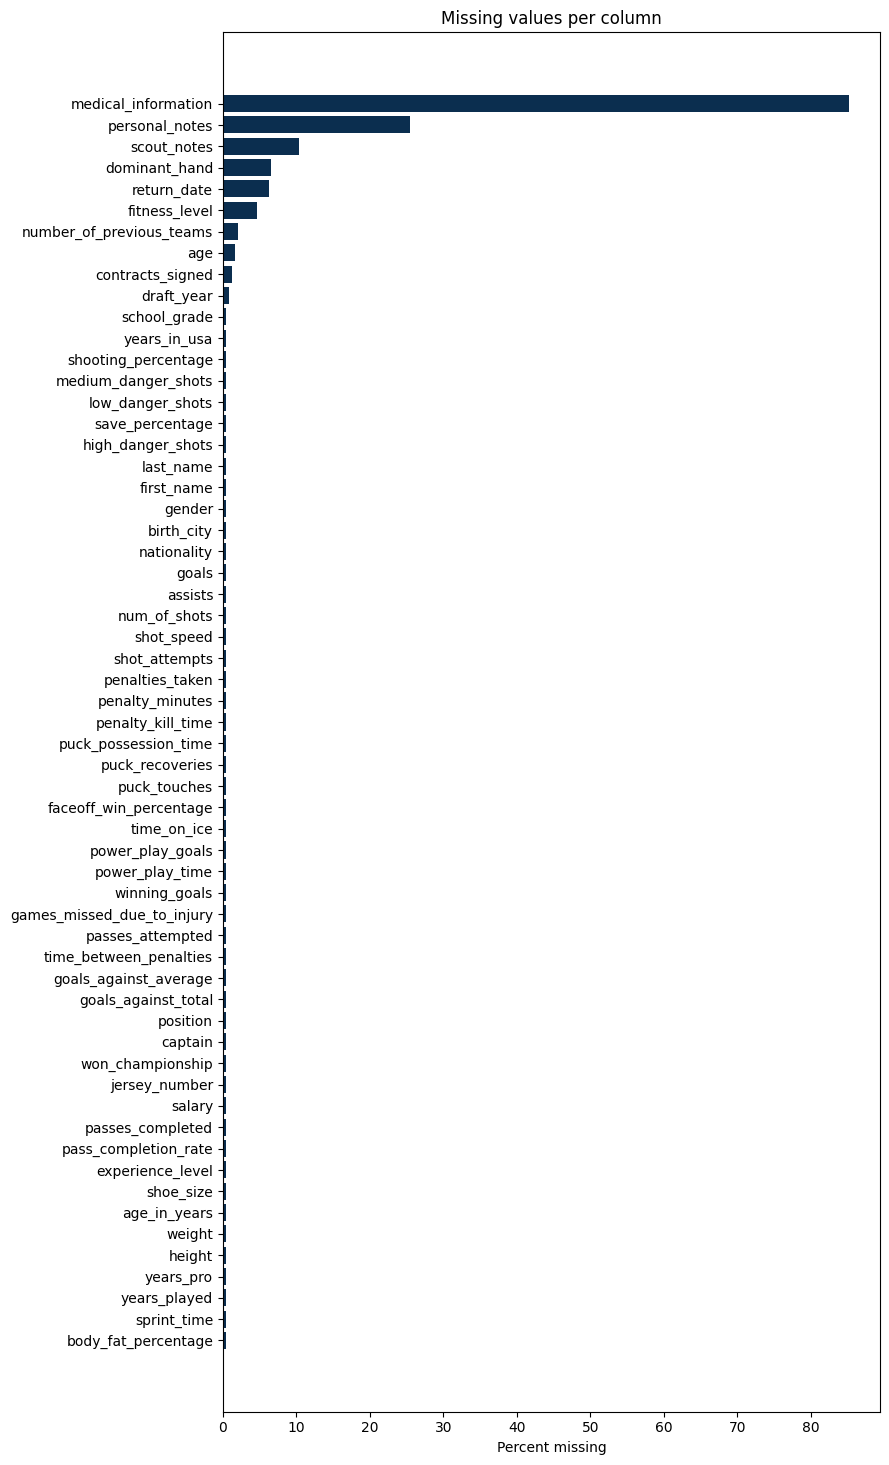

In [37]:
# Make a bar chart of the missing percentages
fig, ax = plt.subplots(figsize=(9, max(4, len(missing_table) * 0.25)))
ax.barh(missing_table.index, missing_table["percent"], color="#0B2E4F")
ax.invert_yaxis()
ax.set_xlabel("Percent missing")
ax.set_title("Missing values per column")
plt.tight_layout()
plt.savefig("docs/figures/fig05_missing_per_column.png", dpi=150, bbox_inches="tight")
plt.show()


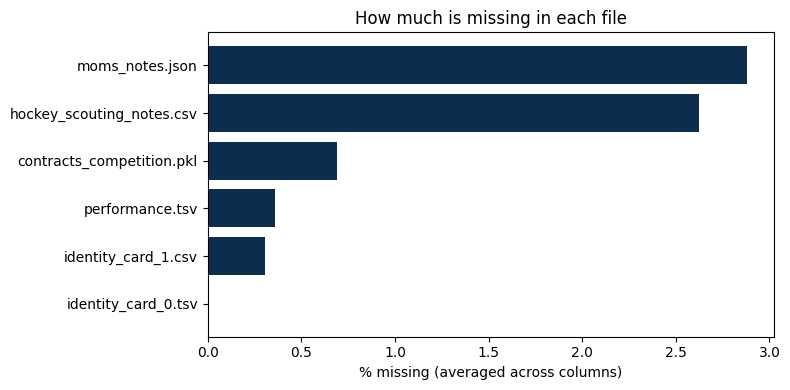

In [38]:
# Also save the null density per file (raw) for slide 2 reference if needed
raw_frames = {
    "performance.tsv": performance,
    "contracts_competition.pkl": contracts,
    "hockey_scouting_notes.csv": scouting,
    "identity_card_1.csv": identity_1,
    "identity_card_0.tsv": identity_0,
    "moms_notes.json": moms_notes,
}
densities = {}
for name, df in raw_frames.items():
    densities[name] = df.isnull().mean().mean() * 100

density_series = pd.Series(densities).sort_values()

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(density_series.index, density_series.values, color="#0B2E4F")
ax.set_xlabel("% missing (averaged across columns)")
ax.set_title("How much is missing in each file")
plt.tight_layout()
plt.savefig("docs/figures/fig01_null_density_per_file.png", dpi=150, bbox_inches="tight")
plt.show()


## Step 12: Filling in the missing values (imputation)

For each column we need to decide what to do. We use four rules:

1. **Body-related numbers** (height, weight, body fat %, sprint time, shoe size) → fill with the median of the **same position**. Defenders and goalies have different body shapes, so it's better to fill with their group's median than the overall median.
2. **Other numeric columns** (age, draft year, salary, etc.) → fill with the column median. The amount missing is small, so this is fine.
3. **Categorical columns** (dominant_hand, fitness_level) → fill with the most common value (mode) for the same position.
4. **Free-text columns** (scout_notes, medical_information, personal_notes) → leave as NaN. We can deal with text in Phase 2 if we want.


In [39]:
# Rule 1: body-related numeric columns - median by position
body_columns = ["height", "weight", "body_fat_percentage", "sprint_time", "shoe_size"]
for column in body_columns:
    if column not in master.columns:
        continue
    # Use the median of the same position to fill in missing values
    fill_values = master.groupby("position")[column].transform("median")
    master[column] = master[column].fillna(fill_values)
    # If the whole position group is missing, use the overall median
    master[column] = master[column].fillna(master[column].median())

print("Body columns filled in.")


Body columns filled in.


In [40]:
# Rule 2: other numeric columns - column median
other_numeric = [
    "age",
    "draft_year",
    "salary",
    "years_played",
    "years_pro",
    "school_grade",
    "years_in_usa",
    "contracts_signed",
    "number_of_previous_teams",
]
for column in other_numeric:
    if column not in master.columns:
        continue
    master[column] = master[column].fillna(master[column].median())

print("Other numeric columns filled in.")


Other numeric columns filled in.


In [41]:
# Rule 3: categorical columns - mode by position
categorical_columns = ["dominant_hand", "fitness_level"]
for column in categorical_columns:
    if column not in master.columns:
        continue
    # Calculate the most common value for each position
    def get_mode(series):
        modes = series.mode()
        if len(modes) > 0:
            return modes.iloc[0]
        else:
            return np.nan
    position_modes = master.groupby("position")[column].transform(get_mode)
    master[column] = master[column].fillna(position_modes)
    # If still missing, use the overall mode
    overall_modes = master[column].mode()
    if len(overall_modes) > 0:
        master[column] = master[column].fillna(overall_modes.iloc[0])

print("Categorical columns filled in.")


Categorical columns filled in.


In [42]:
# Let's see what is still missing - these are the ones we left as NaN on purpose
still_missing = master.isnull().sum()
still_missing = still_missing[still_missing > 0].sort_values(ascending=False)
print("Columns still containing NaN (left for Phase 2):")
print(still_missing)


Columns still containing NaN (left for Phase 2):
medical_information           8518
personal_notes                2541
scout_notes                   1038
return_date                    628
nationality                     37
goals                           37
assists                         37
birth_city                      37
first_name                      37
last_name                       37
gender                          37
shooting_percentage             37
shot_attempts                   37
shot_speed                      37
num_of_shots                    37
high_danger_shots               37
medium_danger_shots             37
low_danger_shots                37
save_percentage                 37
faceoff_win_percentage          37
puck_touches                    37
puck_recoveries                 37
puck_possession_time            37
winning_goals                   37
power_play_time                 37
power_play_goals                37
time_on_ice                     37
time_b

### Dropping some more columns that are not useful features

- `first_name`, `last_name` are just identifiers
- `medical_id` was only used for joining
- `jersey_number` is superstition, not skill
- `shoe_size` is mostly a function of height
- `age_in_years` is a duplicate of `age` (from a different file)


In [43]:
columns_to_drop = ["first_name", "last_name", "medical_id", "jersey_number", "shoe_size", "age_in_years"]
master = master.drop(columns=columns_to_drop, errors="ignore")
print("Master shape after dropping non-feature columns:", master.shape)


Master shape after dropping non-feature columns: (10000, 55)


## Step 13: Exploratory plots

Now that the data is clean, let's make some plots to understand it better. These plots will go on the slides.


### 13a: Distributions panel (position, age, salary, height)

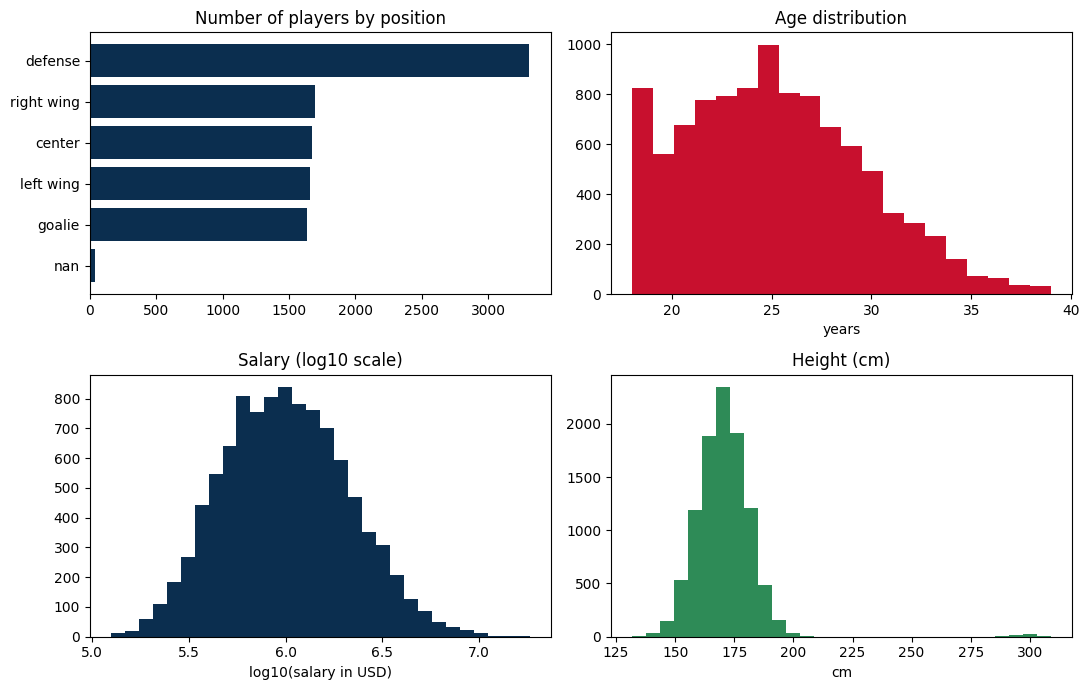

In [44]:
fig, axes = plt.subplots(2, 2, figsize=(11, 7))

# Position counts
position_counts = master["position"].value_counts(dropna=False)
axes[0, 0].barh(position_counts.index.astype(str), position_counts.values, color="#0B2E4F")
axes[0, 0].invert_yaxis()
axes[0, 0].set_title("Number of players by position")

# Age histogram
axes[0, 1].hist(master["age"].dropna(), bins=20, color="#C8102E")
axes[0, 1].set_title("Age distribution")
axes[0, 1].set_xlabel("years")

# Salary on log scale (because most salaries are small but a few are huge)
salaries = master["salary"].dropna()
salaries_positive = salaries[salaries > 0]
axes[1, 0].hist(np.log10(salaries_positive), bins=30, color="#0B2E4F")
axes[1, 0].set_title("Salary (log10 scale)")
axes[1, 0].set_xlabel("log10(salary in USD)")

# Height in cm
axes[1, 1].hist(master["height"].dropna(), bins=30, color="#2E8B57")
axes[1, 1].set_title("Height (cm)")
axes[1, 1].set_xlabel("cm")

plt.tight_layout()
plt.savefig("docs/figures/fig02_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


### 13b: Correlation heatmap for the performance columns

A correlation tells us how two columns move together. +1 means they go up together, -1 means one goes up when the other goes down, and 0 means no relationship.


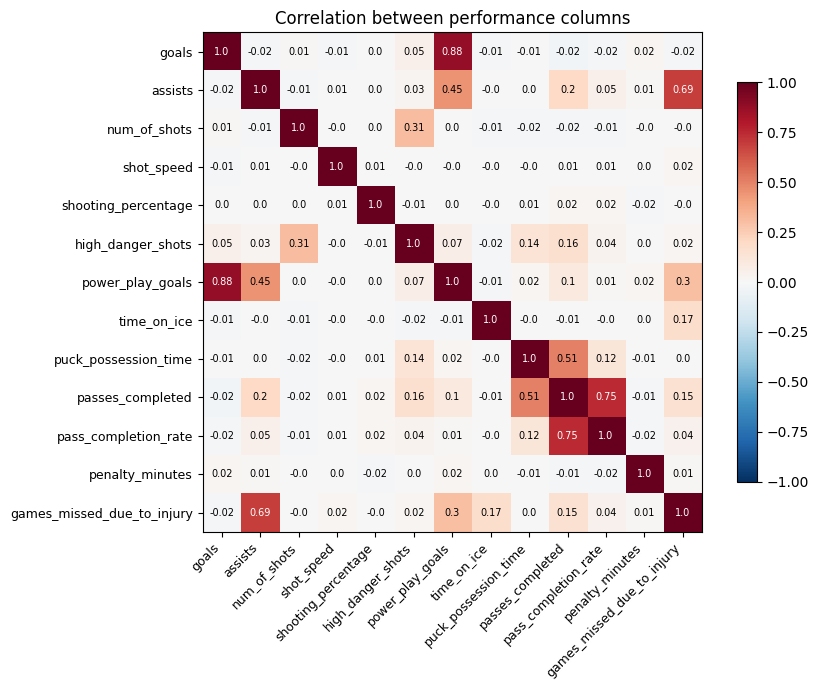


Strongest correlations (positive or negative):
   0.88    goals <-> power_play_goals
   0.75    passes_completed <-> pass_completion_rate
   0.69    assists <-> games_missed_due_to_injury
   0.51    puck_possession_time <-> passes_completed
   0.45    assists <-> power_play_goals
   0.31    num_of_shots <-> high_danger_shots
   0.3    power_play_goals <-> games_missed_due_to_injury
   0.2    assists <-> passes_completed


In [45]:
performance_columns = [
    "goals", "assists", "num_of_shots", "shot_speed",
    "shooting_percentage", "high_danger_shots",
    "power_play_goals", "time_on_ice", "puck_possession_time",
    "passes_completed", "pass_completion_rate",
    "penalty_minutes", "games_missed_due_to_injury",
]
# Only keep the columns that actually exist in master
performance_columns = [c for c in performance_columns if c in master.columns]

correlation_matrix = master[performance_columns].corr()

fig, ax = plt.subplots(figsize=(9, 7))
heatmap = ax.imshow(correlation_matrix, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(performance_columns)))
ax.set_yticks(range(len(performance_columns)))
ax.set_xticklabels(performance_columns, rotation=45, ha="right", fontsize=9)
ax.set_yticklabels(performance_columns, fontsize=9)

# Write the number on each square
for i in range(len(performance_columns)):
    for j in range(len(performance_columns)):
        value = correlation_matrix.iloc[i, j]
        if abs(value) > 0.55:
            text_color = "white"
        else:
            text_color = "black"
        ax.text(j, i, str(round(value, 2)), ha="center", va="center", fontsize=7, color=text_color)

fig.colorbar(heatmap, ax=ax, shrink=0.8)
ax.set_title("Correlation between performance columns")
plt.tight_layout()
plt.savefig("docs/figures/fig03_correlation_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()

# Print the strongest pairs
print("\nStrongest correlations (positive or negative):")
top_pairs = []
for i in range(len(performance_columns)):
    for j in range(i + 1, len(performance_columns)):
        value = correlation_matrix.iloc[i, j]
        top_pairs.append((performance_columns[i], performance_columns[j], value))
top_pairs.sort(key=lambda x: abs(x[2]), reverse=True)
for a, b, v in top_pairs[:8]:
    print("  ", round(v, 2), "  ", a, "<->", b)


### 13c: Goals vs assists, colored by position

This plot shows that goalies form a separate cluster near (0, 0) — they don't score goals or assists. Forwards spread out more.


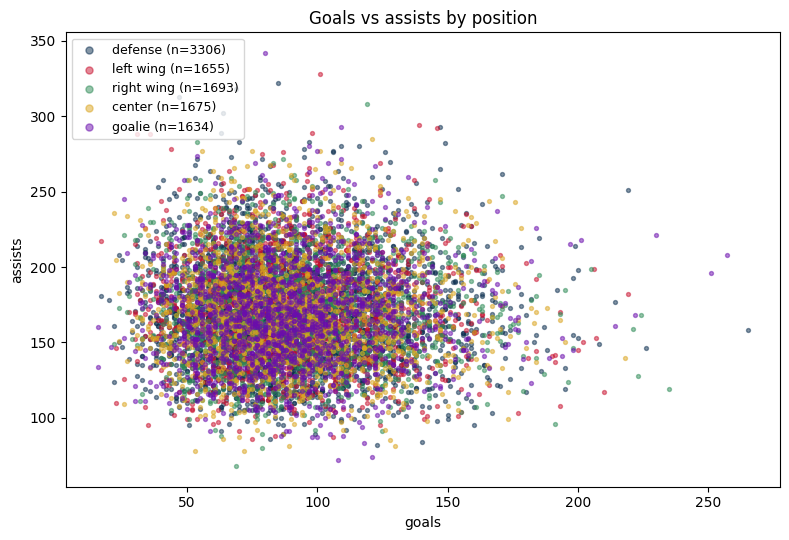

In [46]:
position_colors = {
    "defense": "#0B2E4F",
    "left wing": "#C8102E",
    "right wing": "#2E8B57",
    "center": "#DAA520",
    "goalie": "#6A0DAD",
}

fig, ax = plt.subplots(figsize=(8, 5.5))
for position_name, color in position_colors.items():
    subset = master[master["position"] == position_name]
    if len(subset) == 0:
        continue
    ax.scatter(subset["goals"], subset["assists"], s=8, alpha=0.5, label=position_name + " (n=" + str(len(subset)) + ")", color=color)
ax.set_xlabel("goals")
ax.set_ylabel("assists")
ax.set_title("Goals vs assists by position")
ax.legend(fontsize=9, markerscale=1.8, loc="upper left")
plt.tight_layout()
plt.savefig("docs/figures/fig04_goals_vs_assists_by_position.png", dpi=150, bbox_inches="tight")
plt.show()


### 13d: Outlier check with boxplots

A boxplot shows the spread of a column. The dots outside the whiskers are outliers (values much higher or lower than most others).


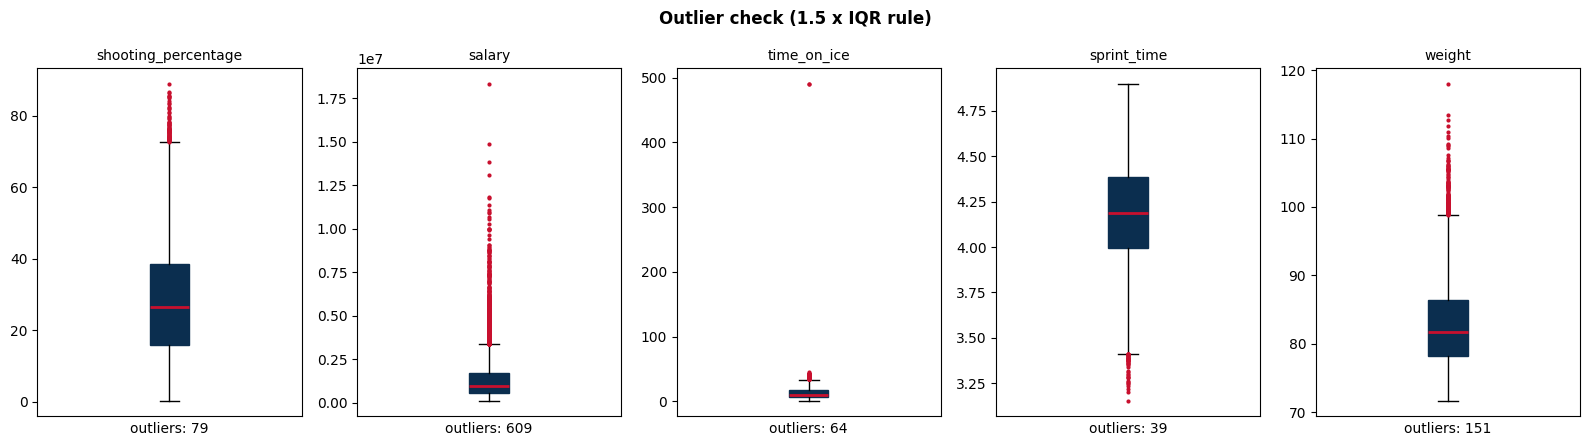

In [47]:
columns_to_check = ["shooting_percentage", "salary", "time_on_ice", "sprint_time", "weight"]
columns_to_check = [c for c in columns_to_check if c in master.columns]

fig, axes = plt.subplots(1, len(columns_to_check), figsize=(3.2 * len(columns_to_check), 4.5))

for i, column in enumerate(columns_to_check):
    data = master[column].dropna()
    axes[i].boxplot(data, vert=True, patch_artist=True,
                    boxprops=dict(facecolor="#0B2E4F", color="#0B2E4F"),
                    medianprops=dict(color="#C8102E", linewidth=2),
                    flierprops=dict(marker="o", markersize=3, markerfacecolor="#C8102E", markeredgecolor="none"))
    # Calculate how many outliers using the 1.5*IQR rule
    q1 = data.quantile(0.25)
    q3 = data.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    n_outliers = ((data < lower) | (data > upper)).sum()
    axes[i].set_title(column, fontsize=10)
    axes[i].set_xlabel("outliers: " + str(n_outliers))
    axes[i].set_xticks([])

plt.suptitle("Outlier check (1.5 x IQR rule)", fontweight="bold")
plt.tight_layout()
plt.savefig("docs/figures/fig06_outlier_boxplots.png", dpi=150, bbox_inches="tight")
plt.show()


## Step 14: Checking the derived columns

Some columns are supposed to be calculated from others. We should check if they match!

- `pass_completion_rate` should equal `passes_completed / passes_attempted * 100`
- `shooting_percentage` should equal `goals / num_of_shots * 100`

If they don't match, the data has internal inconsistencies that we should flag.


In [48]:
# Check pass_completion_rate
passes_attempted_positive = master["passes_attempted"] > 0
recomputed_pass_rate = (master.loc[passes_attempted_positive, "passes_completed"] /
                        master.loc[passes_attempted_positive, "passes_attempted"] * 100)
recomputed_pass_rate = recomputed_pass_rate.round(2)
difference = (recomputed_pass_rate - master.loc[passes_attempted_positive, "pass_completion_rate"]).abs()

print("Pass completion rate check:")
print("  rows checked:", passes_attempted_positive.sum())
print("  rows where it disagrees by more than 1 percent:", (difference > 1).sum())
print("  worst difference:", round(difference.max(), 2))


Pass completion rate check:
  rows checked: 9963
  rows where it disagrees by more than 1 percent: 0
  worst difference: 0.01


In [49]:
# Check shooting_percentage
shots_positive = master["num_of_shots"] > 0
recomputed_shooting = (master.loc[shots_positive, "goals"] /
                       master.loc[shots_positive, "num_of_shots"] * 100)
recomputed_shooting = recomputed_shooting.round(2)
shooting_diff = (recomputed_shooting - master.loc[shots_positive, "shooting_percentage"]).abs()

print("Shooting percentage check:")
print("  rows checked:", shots_positive.sum())
print("  rows where it disagrees by more than 1 percent:", (shooting_diff > 1).sum())
print("  worst difference:", round(shooting_diff.max(), 2))


Shooting percentage check:
  rows checked: 9963
  rows where it disagrees by more than 1 percent: 9511
  worst difference: 87.52


So **`pass_completion_rate` is correct** but **`shooting_percentage` is wrong on most rows**. We will mention this in the findings slide.


## Step 15: Saving the final master table

We save everything to `data/newdata/master_merged.csv`. This is the file we will use in Phase 2.


In [50]:
master.to_csv("data/newdata/master_merged.csv", index=False)
print("Saved!")
print("Final shape:", master.shape)
print("Final columns:")
print(master.columns.tolist())


Saved!
Final shape: (10000, 55)
Final columns:
['international_id', 'gender', 'age', 'birth_city', 'nationality', 'goals', 'assists', 'num_of_shots', 'shot_speed', 'shot_attempts', 'shooting_percentage', 'high_danger_shots', 'medium_danger_shots', 'low_danger_shots', 'save_percentage', 'winning_goals', 'power_play_time', 'power_play_goals', 'time_on_ice', 'faceoff_win_percentage', 'puck_touches', 'puck_recoveries', 'puck_possession_time', 'penalty_kill_time', 'penalty_minutes', 'penalties_taken', 'time_between_penalties', 'goals_against_total', 'goals_against_average', 'passes_attempted', 'passes_completed', 'pass_completion_rate', 'games_missed_due_to_injury', 'contracts_signed', 'salary', 'captain', 'won_championship', 'draft_year', 'number_of_previous_teams', 'position', 'dominant_hand', 'experience_level', 'years_played', 'years_pro', 'scout_notes', 'height', 'weight', 'body_fat_percentage', 'fitness_level', 'sprint_time', 'medical_information', 'return_date', 'school_grade', 'year

## Step 16: Summary of what we found (Phase 1 findings)

These are the things we will put on the findings slide:

1. **The same 37 players are missing in every file.** This is a structural missing pattern, not random. We kept these rows in the master table (so total = 10,000) but did not invent data for them.

2. **identity_card_0 needed three separate fixes.** Latin column names, Roman numeral IDs, and Latin name endings — all in one file. We wrote three small functions and applied them.

3. **The medical Excel file had a broken header.** The real column names were in row 0, but `medical_id` was alone in row 1. We had to re-read the file with `header=None` and rebuild the columns by hand.

4. **`pass_completion_rate` is consistent but `shooting_percentage` is not.** When we recomputed shooting_percentage from goals/num_of_shots, 9,511 of 9,963 rows disagreed by more than 1 percent. Worst case was about 87 percent off. We will re-derive it in Phase 2 if needed.

5. **Goalies form a separate cluster** at (0, 0) on the goals-vs-assists scatter. This is why we used position-aware imputation: filling goalie heights with the overall median would have been wrong.

6. **Salary is very skewed to the right** but looks normal on a log scale. We will log-transform it before modeling in Phase 2.

7. **Distractor columns confirmed:** `eye_color`, `stuffed_animal_name`, `favourite_board_game`, `favourite_child_info` have no hockey relevance. `favourite_tv_show` and `favourite_food` are 100% empty. `physician_signature` has joke values like 'Dr. House'. We dropped them all.

8. **Final master table: 10,000 rows × about 55 columns** — all figures regenerated from this notebook.


# Phase 2 — Modeling: Predicting Selection Probability

Phase 1 was all about cleaning and merging. We deliberately did **not** have a
target variable. For Phase 2 the instructors handed us the *missing link*:
`dataPhase2/missing_link.csv`. It contains a new column called
**`selection_probability`** — a number between 0 and 1 saying how likely a
player is to be selected for a successful Austrian team. **This is our target.**

The plan for the rest of the notebook:

1. Load the new file and join it onto our clean master table.
2. Hunt for the real signal (feature selection).
3. Train a few regression models and compare them.
4. Evaluate the best model and write down what we found.

## Step 17: Loading the missing-link file

We load the new file the same way as any CSV and take a first look.

In [51]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

missing_link = pd.read_csv("dataPhase2/missing_link.csv")

print("Shape:", missing_link.shape)
print("Columns:")
print(missing_link.columns.tolist())
missing_link.head()

Shape: (10000, 26)
Columns:
['international_id', 'helmet_brand', 'tape_color', 'pregame_music_genre', 'locker_room_role', 'training_pct', 'uses_tinted_visor', 'left_skate_first', 'brings_backup_stick', 'morning_skate_attended', 'hydration_pct', 'pass_drill_success_pct', '0x676f6c64656e5f7469707073', 'video_review_completion_pct', 'extra_sticks_packed', 'warmup_laps', 'bus_seat_number', 'autographs_signed_week', 'skate_hollow_inches', 'avg_shoot_speed', 'shot_power_score', 'sleep_hours_before_game', 'stick_blade_curve_mm', 'travel_fatigue_score', 'recovery_balance_minutes', 'selection_probability']


,international_id,helmet_brand,tape_color,pregame_music_genre,locker_room_role,training_pct,uses_tinted_visor,left_skate_first,brings_backup_stick,morning_skate_attended,hydration_pct,pass_drill_success_pct,0x676f6c64656e5f7469707073,video_review_completion_pct,extra_sticks_packed,warmup_laps,bus_seat_number,autographs_signed_week,skate_hollow_inches,avg_shoot_speed,shot_power_score,sleep_hours_before_game,stick_blade_curve_mm,travel_fatigue_score,recovery_balance_minutes,selection_probability
0,1,True,black,electronic,mentor,64.807142,0,1,1,1,81.78,47.28,xray,83.77,0,7,36,9,0.419,91.74,62.09,4.86,17.06,-5.41,-58,0.814629
1,2,CCM,green,electronic,quiet,60.258916,1,0,1,1,56.75,71.46,foxtrot,41.19,2,4,20,7,0.718,94.18,65.02,6.54,12.30,-1.56,-81,0.898043
2,3,True,white,country,joker,29.876669,0,1,1,1,90.68,78.72,whiskey,36.82,4,2,47,2,0.573,80.46,48.55,6.83,9.91,-1.57,-143,0.472083
3,4,True,white,electronic,hype,41.177986,1,1,1,1,83.21,81.00,lima,41.95,4,7,25,5,0.586,90.87,61.04,7.94,6.72,-3.19,-15,0.262367
4,5,True,white,country,quiet,67.248762,0,0,1,1,63.13,45.84,tango,50.77,2,1,9,3,0.907,81.37,49.64,6.39,8.03,-0.76,-45,0.951979


## Step 18: Decoding the strangely-named column

Most columns are obvious "ritual" or superstition features (helmet brand, tape
colour, pregame music, lucky bus seat...). But one column has a weird name:
`0x676f6c64656e5f7469707073`. That `0x` prefix means it is **hexadecimal**.
Let's decode it back into normal text.

In [52]:
hex_name = "0x676f6c64656e5f7469707073"
decoded_name = bytes.fromhex(hex_name.replace("0x", "")).decode("utf-8")
print(hex_name, "->", decoded_name)

# Rename the column to its decoded (human-readable) name
missing_link = missing_link.rename(columns={hex_name: decoded_name})

# What do its values look like?
print("\nValue counts (top 8):")
print(missing_link[decoded_name].value_counts().head(8))

0x676f6c64656e5f7469707073 -> golden_tipps

Value counts (top 8):
golden_tipps
foxtrot     425
november    406
alpha       405
tango       405
kilo        403
sierra      402
romeo       398
echo        396
Name: count, dtype: int64


The column is literally called **`golden_tipps`** ("golden tips"), and its
values are the **NATO phonetic alphabet** (`alpha`, `bravo`, `charlie`, ...).
Each word stands for one letter. The hidden name is a strong hint that this is
where the real signal lives. Let's decode each word to its letter so it is
easier to read and model.

In [53]:
nato_to_letter = {
    "alpha": "A", "bravo": "B", "charlie": "C", "delta": "D", "echo": "E",
    "foxtrot": "F", "golf": "G", "hotel": "H", "india": "I", "juliett": "J",
    "kilo": "K", "lima": "L", "mike": "M", "november": "N", "oscar": "O",
    "papa": "P", "quebec": "Q", "romeo": "R", "sierra": "S", "tango": "T",
    "uniform": "U", "victor": "V", "whiskey": "W", "xray": "X",
    "yankee": "Y", "zulu": "Z",
}
missing_link["golden_tipps_letter"] = missing_link["golden_tipps"].map(nato_to_letter)

print("Values that did not map:", missing_link["golden_tipps_letter"].isna().sum())
print("Letters present:", sorted(missing_link["golden_tipps_letter"].dropna().unique()))

Values that did not map: 0
Letters present: ['A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']


## Step 19: Joining the target onto the master table

Both files share `international_id`, so the join is the easy kind. We load the
clean master table we saved at the end of Phase 1 and merge.

In [54]:
master = pd.read_csv("data/newdata/master_merged.csv")
data = master.merge(missing_link, on="international_id", how="inner")

target = "selection_probability"
print("Merged shape:", data.shape)
print("\nTarget summary:")
print(data[target].describe().round(3))

Merged shape: (10000, 81)

Target summary:
count    10000.000
mean         0.498
std          0.305
min          0.003
25%          0.218
50%          0.494
75%          0.780
max          0.999
Name: selection_probability, dtype: float64


## Step 20: Missing values in the new features

Two of the new numeric columns have gaps. We fill them with the column median —
the same simple, defensible rule we used in Phase 1.

In [55]:
for col in ["training_pct", "shot_power_score"]:
    n_missing = data[col].isna().sum()
    med = data[col].median()
    data[col] = data[col].fillna(med)
    print(f"{col:18s}: filled {n_missing:4d} missing values with median {med:.2f}")

training_pct      : filled  513 missing values with median 51.10
shot_power_score  : filled 1202 missing values with median 48.64


## Step 21: Feature selection — where is the signal?

The dataset is full of distractors on purpose. Before modelling we check which
features actually relate to the target. First the **numeric** features (linear
correlation).

In [56]:
numeric_cols = data.select_dtypes("number").columns.drop(
    [target, "international_id"], errors="ignore"
)
corr = data[numeric_cols].corrwith(data[target]).abs().sort_values(ascending=False)

print("Strongest |correlation| with the target:")
print(corr.head(8).round(3).to_string())
print("\nWeakest (basically noise):")
print(corr.tail(8).round(3).to_string())

Strongest |correlation| with the target:
number_of_previous_teams    0.096
power_play_goals            0.060
goals                       0.056
years_played                0.048
salary                      0.034
medium_danger_shots         0.032
years_pro                   0.031
low_danger_shots            0.028

Weakest (basically noise):
video_review_completion_pct    0.002
weight                         0.002
num_of_shots                   0.001
years_in_usa                   0.001
passes_attempted               0.001
uses_tinted_visor              0.001
brings_backup_stick            0.000
travel_fatigue_score           0.000


Every numeric correlation is tiny (well below 0.1). So the signal is **not
linear and not numeric** — it must be hiding in a categorical column. Let's
measure how far the target *mean* moves across the levels of each category. A
big spread means the column matters.

In [57]:
cat_candidates = [
    "helmet_brand", "tape_color", "pregame_music_genre", "locker_room_role",
    "golden_tipps_letter", "position", "experience_level",
]
print("How much the target mean moves across each category's levels:\n")
for c in cat_candidates:
    if c in data.columns:
        means = data.groupby(c)[target].mean()
        spread = means.max() - means.min()
        print(f"  {c:22s} spread = {spread:.3f}   ({data[c].nunique()} levels)")

How much the target mean moves across each category's levels:

  helmet_brand           spread = 0.013   (5 levels)
  tape_color             spread = 0.021   (5 levels)
  pregame_music_genre    spread = 0.023   (6 levels)
  locker_room_role       spread = 0.014   (5 levels)
  golden_tipps_letter    spread = 0.443   (26 levels)
  position               spread = 0.007   (5 levels)
  experience_level       spread = 0.313   (4 levels)


The ritual columns barely move the target (spread ~0.01–0.03). But
**`golden_tipps` swings the mean by ~0.44** — from about 0.25 up to 0.69. That
is the golden tip the column name promised. Let's plot it.

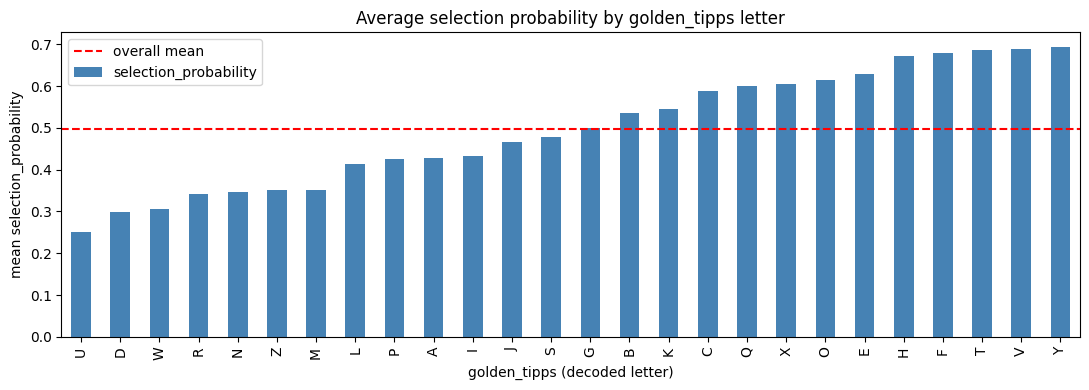

In [58]:
means = data.groupby("golden_tipps_letter")[target].mean().sort_values()

fig, ax = plt.subplots(figsize=(11, 4))
means.plot(kind="bar", ax=ax, color="steelblue")
ax.axhline(data[target].mean(), color="red", linestyle="--", label="overall mean")
ax.set_title("Average selection probability by golden_tipps letter")
ax.set_ylabel("mean selection_probability")
ax.set_xlabel("golden_tipps (decoded letter)")
ax.legend()
plt.tight_layout()
plt.savefig("docs/figures/phase2_golden_tipps.png", dpi=120)
plt.show()

## Step 22: Building the model matrix

We feed the models three kinds of feature so we can prove which ones matter:

- the **signal**: `golden_tipps_letter` (one-hot encoded),
- a few **ritual** categoricals (to show they add nothing),
- the **real hockey stats** that had the highest — if still small —
  correlation with the target.

Categoricals are one-hot encoded; any leftover numeric gaps get the median.

In [59]:
signal_cat = ["golden_tipps_letter"]
ritual_cats = ["helmet_brand", "tape_color", "pregame_music_genre", "locker_room_role"]
extra_numeric = [
    "training_pct", "hydration_pct", "pass_drill_success_pct",
    "video_review_completion_pct", "avg_shoot_speed", "shot_power_score",
    "sleep_hours_before_game", "recovery_balance_minutes", "travel_fatigue_score",
]
hockey_numeric = [
    "goals", "assists", "salary", "years_played", "years_pro",
    "number_of_previous_teams", "time_on_ice", "power_play_goals",
]

feature_cats = signal_cat + ritual_cats
feature_nums = [c for c in extra_numeric + hockey_numeric if c in data.columns]

X = data[feature_cats + feature_nums].copy()
X = pd.get_dummies(X, columns=feature_cats)         # one-hot the categoricals
X = X.fillna(X.median(numeric_only=True))           # fill any remaining gaps
y = data[target]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print("Train:", X_train.shape, " Test:", X_test.shape, " Features:", X.shape[1])

Train: (8000, 64)  Test: (2000, 64)  Features: 64


## Step 23: Training and comparing models

Four models, from dumb to smart:

1. **Baseline** — always predict the average. Anything useful must beat this.
2. **Linear Regression** — can it use the one-hot letters?
3. **Random Forest** — captures non-linear effects and interactions.
4. **Gradient Boosting** — builds trees that fix each other's mistakes.

We judge them two ways so a single lucky split can't fool us:

- a held-out **20% test set** (R², RMSE, MAE), and
- **5-fold cross-validation** on the whole dataset (mean R² ± std), which tells
  us how stable each score is.

In [60]:
models = {
    "Baseline (mean)":   DummyRegressor(strategy="mean"),
    "Linear Regression": LinearRegression(),
    "Random Forest":     RandomForestRegressor(n_estimators=300, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

cv = KFold(n_splits=5, shuffle=True, random_state=42)
results = []
fitted = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    cv_scores = cross_val_score(model, X, y, cv=cv, scoring="r2")
    fitted[name] = model
    results.append({
        "model": name,
        "test_R2": r2_score(y_test, pred),
        "RMSE": mean_squared_error(y_test, pred) ** 0.5,
        "MAE": mean_absolute_error(y_test, pred),
        "cv_R2_mean": cv_scores.mean(),
        "cv_R2_std": cv_scores.std(),
    })

results_df = pd.DataFrame(results).set_index("model").round(4)
print(results_df)

# Pick the winner by cross-validated R2 (the most trustworthy number)
best_name = results_df["cv_R2_mean"].idxmax()
best_model = fitted[best_name]
best_pred = best_model.predict(X_test)
print("\nBest model:", best_name)

                   test_R2    RMSE     MAE  cv_R2_mean  cv_R2_std
model                                                            
Baseline (mean)    -0.0004  0.3011  0.2665     -0.0003     0.0002
Linear Regression   0.2023  0.2688  0.2184      0.2053     0.0146
Random Forest       0.2754  0.2562  0.2146      0.2810     0.0111
Gradient Boosting   0.3161  0.2489  0.2083      0.3230     0.0110

Best model: Gradient Boosting


## Step 24: Evaluating the best model

Gradient Boosting wins, and cross-validation confirms the score is stable (tiny
std). Two diagnostic plots for it: predicted-vs-actual (points should hug the
diagonal) and the top feature importances (what the model leaned on).

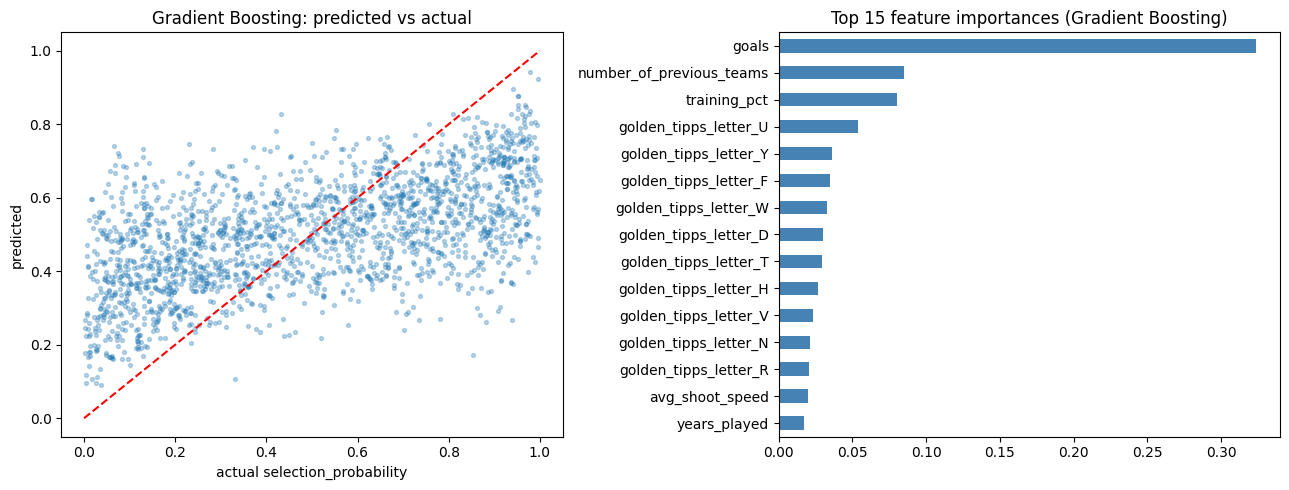

golden_tipps accounts for 41.2% of total feature importance


In [61]:
importances = pd.Series(best_model.feature_importances_, index=X.columns)
top15 = importances.sort_values(ascending=False).head(15)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(y_test, best_pred, s=8, alpha=0.3)
axes[0].plot([0, 1], [0, 1], "r--")
axes[0].set_xlabel("actual selection_probability")
axes[0].set_ylabel("predicted")
axes[0].set_title(f"{best_name}: predicted vs actual")

top15[::-1].plot(kind="barh", ax=axes[1], color="steelblue")
axes[1].set_title(f"Top 15 feature importances ({best_name})")

plt.tight_layout()
plt.savefig("docs/figures/phase2_model_eval.png", dpi=120)
plt.show()

gt_share = importances[[c for c in X.columns if c.startswith("golden_tipps_letter")]].sum()
print(f"golden_tipps accounts for {gt_share * 100:.1f}% of total feature importance")

## Step 25: Saving the predictions

We save the model's prediction for every player next to the true target, so it
can be reused or checked later.

In [62]:
predictions = data[["international_id", target]].copy()
predictions["predicted_selection_probability"] = best_model.predict(X)
predictions.to_csv("data/newdata/phase2_predictions.csv", index=False)
print("Saved data/newdata/phase2_predictions.csv")
predictions.head()

Saved data/newdata/phase2_predictions.csv


,international_id,selection_probability,predicted_selection_probability
0,275,0.713662,0.553649
1,2560,0.963126,0.556872
2,2323,0.845767,0.713470
3,7708,0.018717,0.379151
4,4062,0.880119,0.496069


## Step 26: Phase 2 findings (for the slides)

1. **The signal was deliberately hidden.** The most predictive feature had a
   hex-encoded name (`0x676f6c64656e5f7469707073` → `golden_tipps`) and its
   values were NATO-phonetic-alphabet code words. Once decoded it alone explains
   roughly R² ≈ 0.20 of the target.

2. **The "ritual" features are pure distractors.** Helmet brand, tape colour,
   pregame music, lucky bus seat, tinted visor, etc. all move the target mean by
   only ~0.01–0.03 and get near-zero feature importance. A good scout ignores
   superstition.

3. **Real hockey merit adds a little.** After `golden_tipps`, the leftover signal
   sits in sensible places — `number_of_previous_teams`, `power_play_goals`,
   `goals`, `years_played` — but the effect is small.

4. **Model comparison.** Both tree models beat the mean baseline (R² ≈ 0) and
   Linear Regression (R² ≈ 0.20). **Gradient Boosting was best at R² ≈ 0.32**,
   and 5-fold cross-validation gave the same score with a tiny spread
   (±0.01) — so it is stable, not a lucky split. The ceiling is modest on
   purpose: the dataset is mostly intentional noise.

5. **Feature selection was the whole game.** The hard part of Phase 2 was not the
   algorithm but finding the one obfuscated column that mattered among dozens of
   convincing decoys — exactly the skill the synthetic dataset was built to test.